# Machine Learning Project: Forecasting Corporate Leverage in Vietnam

**Topic:** Du bao don bay tai chinh va canh bao rui ro kiet que tai chinh cho doanh nghiep niem yet Viet Nam  
**Data:** Excel NXT industry screens: Consumer Staples, Industrials, optional Materials  
**Reference style:** CRISP-DM structure inspired by `jasontanx/capstone-project-machine-learning`  
**Finance context:** Capital structure policy, firm value, and Vietnam listed companies from the provided corporate finance report

## Project Objective

The project converts raw cross-sectional Excel industry screens into a firm-year panel and builds two forecasting tasks:

1. **Regression:** predict next-year leverage, measured as `Total Debt / Total Assets`.
2. **Classification:** predict whether a firm is likely to enter a next-year financial distress zone.

The modelling goal is not to prove causality. It is to create a practical early-warning and decision-support pipeline for corporate finance analysis.


## 1. Setup

Run the first code cell if the environment does not already have the required libraries. The notebook intentionally uses standard, lightweight models from scikit-learn so it can run in class or on most laptops.


In [ ]:
import sys
import subprocess
from importlib.util import find_spec

required = {
    "pandas": "pandas",
    "numpy": "numpy",
    "openpyxl": "openpyxl",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

missing = [pkg for module, pkg in required.items() if find_spec(module) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are available.")


All required packages are available.


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 80)
RANDOM_STATE = 42


## 2. Business Understanding

Capital structure decisions affect financing flexibility, cost of capital, firm value, and distress risk. In an emerging market such as Vietnam, leverage can be shaped by bank financing, industry asset structure, profitability, and macro/market conditions.

### Problem Statement

Given historical firm-level financial indicators, can we forecast next-year leverage and identify firms at risk of financial distress?

### Research Questions

- Which firm-level indicators are most predictive of next-year leverage?
- Do profitability, size, market valuation, and debt structure explain changes in leverage?
- Can a machine learning model provide a useful early-warning signal for financial distress?


## 3. Data Understanding

The provided Excel files are exported as industry screens. Each firm is a row, and each financial variable spans `FY0` to `FY-10` across columns.

This notebook uses **Consumer Staples** and **Industrials** by default because they align with the finance report focus on consumer/manufacturing-related sectors. `Materials` is included as an optional third industry for sensitivity testing.

Set `USE_MATERIALS = True` if you want to use all three files.


In [ ]:
DATA_FILES = {
    "Consumer Staples": Path.home() / "Downloads" / "NXT_Consumer Staples.xlsx",
    "Industrials": Path.home() / "Downloads" / "NXT_industrials.xlsx",
    "Materials": Path.home() / "Downloads" / "NXT_materials.xlsx",
}

USE_MATERIALS = False
SELECTED_SECTORS = ["Consumer Staples", "Industrials"] + (["Materials"] if USE_MATERIALS else [])
CURRENT_FY = 2025

for sector in SELECTED_SECTORS:
    assert DATA_FILES[sector].exists(), f"Missing file: {DATA_FILES[sector]}"

print("Selected industry files:")
for sector in SELECTED_SECTORS:
    print(f"- {sector}: {DATA_FILES[sector].name}")


Selected industry files:
- Consumer Staples: NXT_Consumer Staples.xlsx
- Industrials: NXT_industrials.xlsx


In [ ]:
def _normalize_metric_name(name):
    name = str(name).replace("\n", " ").strip()
    name = name.replace("(VND)", "").replace("In the last 11 FY", "").strip()
    mapping = {
        "Total Debt": "total_debt",
        "Total Assets, Reported": "total_assets",
        "Notes Payable/Short Term Debt": "short_term_debt",
        "Return on Assets": "roa",
        "EBIT": "ebit",
        "Interest Expense": "interest_expense",
        "Company Market Capitalization": "market_cap",
        "Revenue": "revenue",
    }
    return mapping.get(name, name.lower().replace(" ", "_").replace("/", "_"))


def load_nxt_screen(path, broad_sector, current_fy=2025):
    raw = pd.read_excel(path, sheet_name="Current Screen Template", header=None)

    metric_groups = []
    col = 4
    while col < raw.shape[1]:
        header = raw.iloc[0, col]
        if pd.isna(header):
            col += 1
            continue
        metric = _normalize_metric_name(header)
        cols = list(range(col, min(col + 11, raw.shape[1])))
        metric_groups.append((metric, cols))
        col += 11

    records = []
    data = raw.iloc[3:].copy()
    for _, row in data.iterrows():
        ticker = row.iloc[0]
        if pd.isna(ticker):
            continue
        base = {
            "ticker": ticker,
            "company_name": row.iloc[1],
            "country": row.iloc[2],
            "gics_industry": row.iloc[3],
            "broad_sector": broad_sector,
        }
        year_records = {}
        for metric, cols in metric_groups:
            for offset, metric_col in enumerate(cols):
                year = current_fy - offset
                year_records.setdefault(year, base.copy())
                year_records[year]["year"] = year
                year_records[year][metric] = row[metric_col]
        records.extend(year_records.values())

    out = pd.DataFrame(records)
    out = out.sort_values(["ticker", "year"]).reset_index(drop=True)
    return out


panel_raw = pd.concat(
    [load_nxt_screen(DATA_FILES[sector], sector, CURRENT_FY) for sector in SELECTED_SECTORS],
    ignore_index=True,
)

print(panel_raw.shape)
panel_raw.head()


(3949, 14)


,ticker,company_name,country,gics_industry,broad_sector,year,total_debt,total_assets,short_term_debt,roa,ebit,interest_expense,market_cap,revenue
0,AAM.HM,Mekong Fisheries JSC,Vietnam,Food Products,Consumer Staples,2015,4.996620e+10,3.219338e+11,0.0,-0.004132,-1.330080e+09,1.045880e+09,8.023293e+10,3.496310e+11
1,AAM.HM,Mekong Fisheries JSC,Vietnam,Food Products,Consumer Staples,2016,0.000000e+00,2.579038e+11,0.0,-0.001359,-3.504172e+08,7.377507e+08,7.344399e+10,2.747782e+11
2,AAM.HM,Mekong Fisheries JSC,Vietnam,Food Products,Consumer Staples,2017,0.000000e+00,2.515606e+11,0.0,-0.007546,-1.898380e+09,0.000000e+00,8.372324e+10,2.241892e+11
3,AAM.HM,Mekong Fisheries JSC,Vietnam,Food Products,Consumer Staples,2018,0.000000e+00,2.299590e+11,0.0,0.015776,3.627789e+09,0.000000e+00,9.079790e+10,2.182639e+11
4,AAM.HM,Mekong Fisheries JSC,Vietnam,Food Products,Consumer Staples,2019,0.000000e+00,2.275080e+11,0.0,0.007620,1.733672e+09,1.497886e+08,1.204522e+11,2.161219e+11


## 4. Data Preparation and Feature Engineering

The raw variables are transformed into finance ratios and lagged predictors. Lagging is important because the model should only use information that would have been available before the forecast year.

Main engineered variables:

- `leverage = total_debt / total_assets`
- `short_debt_ratio = short_term_debt / total_debt`
- `interest_coverage = EBIT / interest expense`
- `market_to_assets = market capitalization / total assets`
- `revenue_growth = annual revenue growth`
- lagged variables for one-year-ahead prediction


In [ ]:
def prepare_financial_panel(df):
    df = df.copy()
    numeric_cols = [
        "total_debt", "total_assets", "short_term_debt", "roa",
        "ebit", "interest_expense", "market_cap", "revenue"
    ]
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df[df["country"].eq("Vietnam")].copy()
    df = df[df["total_assets"].notna() & (df["total_assets"] > 0)].copy()
    df = df.sort_values(["ticker", "year"]).reset_index(drop=True)

    df["leverage"] = df["total_debt"] / df["total_assets"]
    df["short_debt_ratio"] = df["short_term_debt"] / df["total_debt"].replace(0, np.nan)
    df["interest_coverage"] = df["ebit"] / df["interest_expense"].replace(0, np.nan).abs()
    df["market_to_assets"] = df["market_cap"] / df["total_assets"]
    df["firm_size_ln"] = np.log1p(df["total_assets"])
    df["debt_size_ln"] = np.log1p(df["total_debt"].clip(lower=0))
    df["revenue_size_ln"] = np.log1p(df["revenue"].clip(lower=0))
    df["revenue_growth"] = df.groupby("ticker")["revenue"].pct_change()

    df["interest_coverage"] = df["interest_coverage"].replace([np.inf, -np.inf], np.nan).clip(-20, 20)
    df["short_debt_ratio"] = df["short_debt_ratio"].replace([np.inf, -np.inf], np.nan).clip(0, 2)
    df["leverage"] = df["leverage"].replace([np.inf, -np.inf], np.nan).clip(0, 2.5)
    df["market_to_assets"] = df["market_to_assets"].replace([np.inf, -np.inf], np.nan).clip(0, 10)
    df["revenue_growth"] = df["revenue_growth"].replace([np.inf, -np.inf], np.nan).clip(-1, 3)

    feature_base = [
        "leverage", "short_debt_ratio", "roa", "interest_coverage",
        "market_to_assets", "firm_size_ln", "debt_size_ln",
        "revenue_size_ln", "revenue_growth"
    ]
    for col in feature_base:
        df[f"{col}_lag1"] = df.groupby("ticker")[col].shift(1)

    df["leverage_next"] = df.groupby("ticker")["leverage"].shift(-1)
    df["interest_coverage_next"] = df.groupby("ticker")["interest_coverage"].shift(-1)

    industry_year = df.groupby(["broad_sector", "year"])["leverage"].transform("median")
    df["lev_vs_industry"] = df["leverage"] - industry_year
    df["lev_vs_industry_lag1"] = df.groupby("ticker")["lev_vs_industry"].shift(1)

    lev_q75 = df.groupby(["broad_sector", "year"])["leverage"].transform(lambda s: s.quantile(0.75))
    df["distress"] = (
        (df["leverage"] >= lev_q75)
        | (df["interest_coverage"].notna() & (df["interest_coverage"] < 1.0))
        | (df["roa"].notna() & (df["roa"] < 0))
    ).astype(int)
    df["distress_next"] = df.groupby("ticker")["distress"].shift(-1)

    return df


panel = prepare_financial_panel(panel_raw)
print(panel.shape)
panel[["ticker", "company_name", "broad_sector", "year", "leverage", "roa", "interest_coverage", "leverage_next", "distress_next"]].head(12)


(3828, 37)


,ticker,company_name,broad_sector,year,leverage,roa,interest_coverage,leverage_next,distress_next
0,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2015,0.155206,-0.004132,-1.271733,0.00000,1.0
1,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2016,0.000000,-0.001359,-0.474980,0.00000,1.0
2,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2017,0.000000,-0.007546,NaN,0.00000,0.0
3,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2018,0.000000,0.015776,NaN,0.00000,0.0
4,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2019,0.000000,0.007620,11.574126,0.03597,1.0
5,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2020,0.035970,-0.074940,-20.000000,0.00000,1.0
6,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2021,0.000000,-0.020214,-20.000000,0.00000,0.0
7,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2022,0.000000,0.032703,NaN,0.00000,1.0
8,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2023,0.000000,-0.042553,NaN,0.00000,1.0
9,AAM.HM,Mekong Fisheries JSC,Consumer Staples,2024,0.000000,-0.032114,NaN,0.00000,0.0


In [ ]:
model_df = panel.dropna(subset=["leverage_next", "distress_next"]).copy()

feature_cols = [
    "leverage_lag1",
    "short_debt_ratio_lag1",
    "roa_lag1",
    "interest_coverage_lag1",
    "market_to_assets_lag1",
    "firm_size_ln_lag1",
    "debt_size_ln_lag1",
    "revenue_size_ln_lag1",
    "revenue_growth_lag1",
    "lev_vs_industry_lag1",
    "broad_sector",
    "gics_industry",
]

model_df = model_df.dropna(subset=["leverage_lag1"]).copy()
print("Panel rows for modelling:", model_df.shape[0])
print("Companies:", model_df["ticker"].nunique())
print("Years:", int(model_df["year"].min()), "-", int(model_df["year"].max()))
model_df[feature_cols + ["leverage_next", "distress_next"]].head()


Panel rows for modelling: 3108
Companies: 358
Years: 2016 - 2024


,leverage_lag1,short_debt_ratio_lag1,roa_lag1,interest_coverage_lag1,market_to_assets_lag1,firm_size_ln_lag1,debt_size_ln_lag1,revenue_size_ln_lag1,revenue_growth_lag1,lev_vs_industry_lag1,broad_sector,gics_industry,leverage_next,distress_next
1,0.155206,0.0,-0.004132,-1.271733,0.249222,26.497612,24.634613,26.580144,NaN,-0.076956,Consumer Staples,Food Products,0.00000,1.0
2,0.000000,NaN,-0.001359,-0.474980,0.284773,26.275852,0.000000,26.339230,-0.214091,-0.227257,Consumer Staples,Food Products,0.00000,0.0
3,0.000000,NaN,-0.007546,NaN,0.332815,26.250950,0.000000,26.135756,-0.184109,-0.218530,Consumer Staples,Food Products,0.00000,0.0
4,0.000000,NaN,0.015776,NaN,0.394844,26.161167,0.000000,26.108971,-0.026430,-0.211788,Consumer Staples,Food Products,0.03597,1.0
5,0.000000,NaN,0.007620,11.574126,0.529442,26.150451,0.000000,26.099109,-0.009814,-0.202439,Consumer Staples,Food Products,0.00000,1.0


## 5. Exploratory Data Analysis

The visual checks below help answer whether industries have different leverage profiles and whether the target variables are suitable for machine learning.


In [ ]:
summary = (
    panel.groupby("broad_sector")
    .agg(
        firms=("ticker", "nunique"),
        observations=("ticker", "size"),
        avg_leverage=("leverage", "mean"),
        median_roa=("roa", "median"),
        avg_market_to_assets=("market_to_assets", "mean"),
        distress_rate=("distress", "mean"),
    )
    .round(3)
)
summary


,firms,observations,avg_leverage,median_roa,avg_market_to_assets,distress_rate
broad_sector,,,,,,
Consumer Staples,72,765,0.314,0.063,0.781,0.380
Industrials,286,3063,0.226,0.036,0.491,0.443


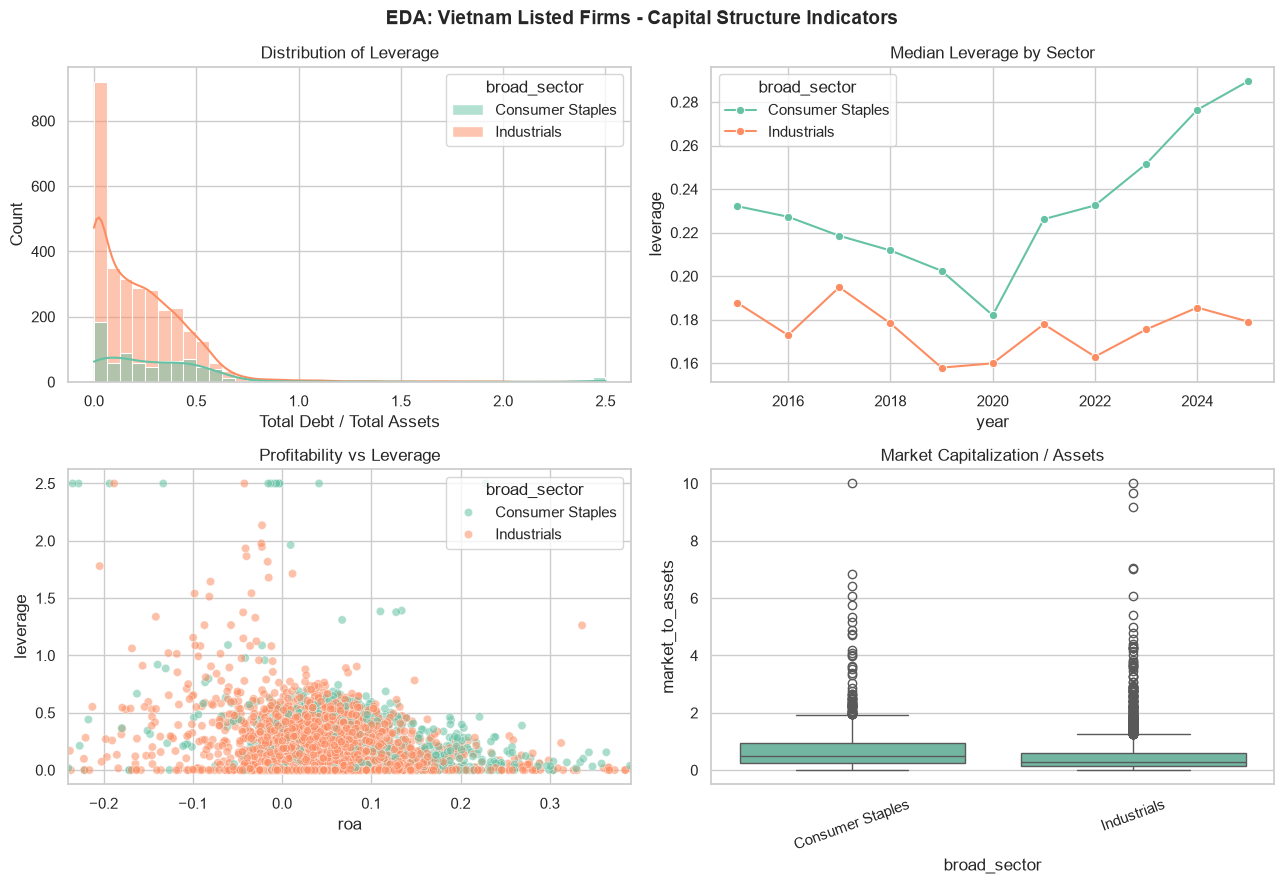

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("EDA: Vietnam Listed Firms - Capital Structure Indicators", fontsize=14, fontweight="bold")

sns.histplot(data=panel, x="leverage", hue="broad_sector", bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Leverage")
axes[0, 0].set_xlabel("Total Debt / Total Assets")

sector_year = panel.groupby(["year", "broad_sector"], as_index=False)["leverage"].median()
sns.lineplot(data=sector_year, x="year", y="leverage", hue="broad_sector", marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Median Leverage by Sector")

sns.scatterplot(data=panel, x="roa", y="leverage", hue="broad_sector", alpha=0.55, ax=axes[1, 0])
axes[1, 0].set_title("Profitability vs Leverage")
axes[1, 0].set_xlim(panel["roa"].quantile(0.01), panel["roa"].quantile(0.99))

sns.boxplot(data=panel, x="broad_sector", y="market_to_assets", ax=axes[1, 1])
axes[1, 1].set_title("Market Capitalization / Assets")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 6. Train-Test Design

Financial panel data should be split by time to reduce look-ahead bias. Earlier years are used for training; later years are kept for testing.


In [ ]:
last_year = int(model_df["year"].max())
test_years = sorted(model_df["year"].unique())[-2:]
train_df = model_df[~model_df["year"].isin(test_years)].copy()
test_df = model_df[model_df["year"].isin(test_years)].copy()

X_train = train_df[feature_cols]
X_test = test_df[feature_cols]
y_train_reg = train_df["leverage_next"]
y_test_reg = test_df["leverage_next"]
y_train_cls = train_df["distress_next"].astype(int)
y_test_cls = test_df["distress_next"].astype(int)

numeric_features = [c for c in feature_cols if c not in ["broad_sector", "gics_industry"]]
categorical_features = ["broad_sector", "gics_industry"]

preprocess_linear = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ]
)

preprocess_tree = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ]
)

print("Train years:", int(train_df["year"].min()), "-", int(train_df["year"].max()), "| rows:", len(train_df))
print("Test years:", test_years, "| rows:", len(test_df))
print("Distress rate train/test:", round(y_train_cls.mean(), 3), round(y_test_cls.mean(), 3))


Train years: 2016 - 2022 | rows: 2396
Test years: [np.int64(2023), np.int64(2024)] | rows: 712
Distress rate train/test: 0.444 0.465


## 7. Task 1 - Regression: Forecast Next-Year Leverage

Models:

- Ridge Regression as an interpretable linear baseline.
- Random Forest Regressor for non-linear relationships.
- Gradient Boosting Regressor for sequential error correction.


In [ ]:
regression_models = {
    "Ridge": Pipeline([
        ("prep", preprocess_linear),
        ("model", Ridge(alpha=2.0, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess_tree),
        ("model", RandomForestRegressor(
            n_estimators=350,
            min_samples_leaf=4,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocess_tree),
        ("model", GradientBoostingRegressor(
            n_estimators=250,
            learning_rate=0.04,
            max_depth=3,
            random_state=RANDOM_STATE,
        )),
    ]),
}

reg_results = []
reg_predictions = {}
for name, model in regression_models.items():
    model.fit(X_train, y_train_reg)
    pred = np.clip(model.predict(X_test), 0, 2.5)
    reg_predictions[name] = pred
    reg_results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test_reg, pred),
        "RMSE": mean_squared_error(y_test_reg, pred) ** 0.5,
        "R2": r2_score(y_test_reg, pred),
    })

reg_results_df = pd.DataFrame(reg_results).sort_values("RMSE")
reg_results_df


,model,MAE,RMSE,R2
0,Ridge,0.086516,0.142775,0.799048
2,Gradient Boosting,0.089361,0.143000,0.798415
1,Random Forest,0.090369,0.148818,0.781677


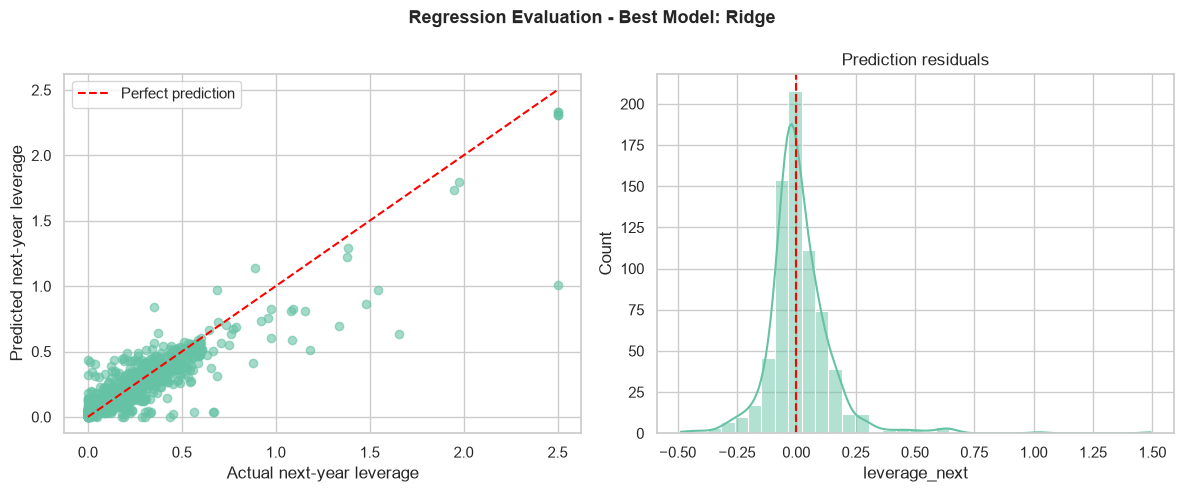

In [ ]:
best_reg_name = reg_results_df.iloc[0]["model"]
best_reg_pred = reg_predictions[best_reg_name]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f"Regression Evaluation - Best Model: {best_reg_name}", fontsize=13, fontweight="bold")

axes[0].scatter(y_test_reg, best_reg_pred, alpha=0.6)
lims = [min(y_test_reg.min(), best_reg_pred.min()), max(y_test_reg.max(), best_reg_pred.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual next-year leverage")
axes[0].set_ylabel("Predicted next-year leverage")
axes[0].legend()

residuals = y_test_reg - best_reg_pred
sns.histplot(residuals, bins=35, kde=True, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Prediction residuals")

plt.tight_layout()
plt.show()


## 8. Task 2 - Classification: Financial Distress Warning

The distress label is rule-based and should be interpreted as an **early-warning proxy**, not a formal default event. A firm is flagged when leverage is high relative to its industry-year peers, interest coverage is weak, or ROA is negative.


In [ ]:
classification_models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess_linear),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess_tree),
        ("model", RandomForestClassifier(
            n_estimators=350,
            min_samples_leaf=4,
            max_features="sqrt",
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

cls_results = []
cls_predictions = {}
for name, model in classification_models.items():
    model.fit(X_train, y_train_cls)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    cls_predictions[name] = (pred, proba)
    cls_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_cls, pred),
        "roc_auc": roc_auc_score(y_test_cls, proba) if y_test_cls.nunique() == 2 else np.nan,
    })

cls_results_df = pd.DataFrame(cls_results).sort_values("roc_auc", ascending=False)
cls_results_df


,model,accuracy,roc_auc
1,Random Forest,0.779494,0.874095
0,Logistic Regression,0.738764,0.834662


Best classifier: Random Forest
              precision    recall  f1-score   support

           0      0.868     0.693     0.771       381
           1      0.713     0.879     0.788       331

    accuracy                          0.779       712
   macro avg      0.791     0.786     0.779       712
weighted avg      0.796     0.779     0.779       712



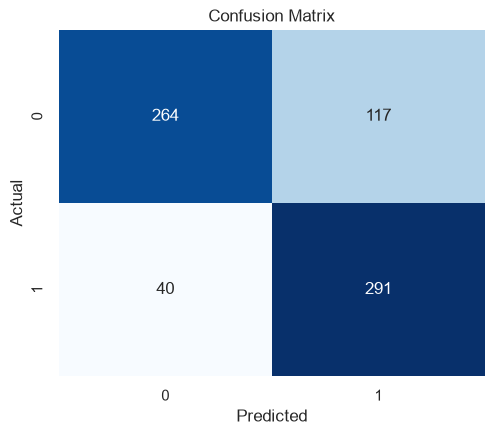

In [ ]:
best_cls_name = cls_results_df.iloc[0]["model"]
best_cls_pred, best_cls_proba = cls_predictions[best_cls_name]

print("Best classifier:", best_cls_name)
print(classification_report(y_test_cls, best_cls_pred, digits=3))

cm = confusion_matrix(y_test_cls, best_cls_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.show()


## 9. Model Interpretability

Feature importance is used to explain which financial drivers matter most. For tree models, importance comes from the fitted model. For logistic regression, coefficient magnitudes are used as a simple proxy.


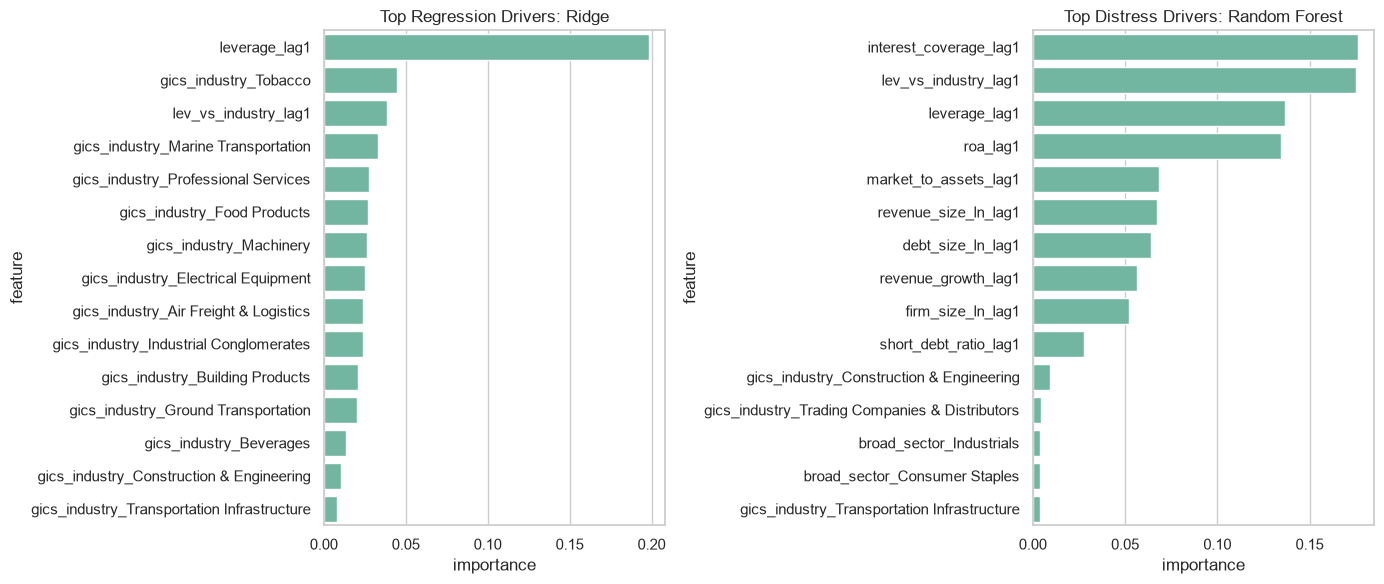

,feature,importance
0,leverage_lag1,0.198276
26,gics_industry_Tobacco,0.044411
9,lev_vs_industry_lag1,0.038747
23,gics_industry_Marine Transportation,0.032781
25,gics_industry_Professional Services,0.027288
18,gics_industry_Food Products,0.026911
22,gics_industry_Machinery,0.026538
17,gics_industry_Electrical Equipment,0.025046
12,gics_industry_Air Freight & Logistics,0.023877
21,gics_industry_Industrial Conglomerates,0.023679


In [ ]:
def get_feature_names(preprocessor):
    names = []
    for block_name, transformer, cols in preprocessor.transformers_:
        if block_name == "remainder" and transformer == "drop":
            continue
        if hasattr(transformer, "named_steps") and "onehot" in transformer.named_steps:
            names.extend(transformer.named_steps["onehot"].get_feature_names_out(cols))
        else:
            names.extend(cols)
    return np.array(names)


def feature_importance_from_pipeline(pipe):
    prep = pipe.named_steps["prep"]
    model = pipe.named_steps["model"]
    names = get_feature_names(prep)
    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
    elif hasattr(model, "coef_"):
        values = np.abs(model.coef_).ravel()
    else:
        values = np.zeros(len(names))
    return pd.DataFrame({"feature": names, "importance": values}).sort_values("importance", ascending=False)


importance_reg = feature_importance_from_pipeline(regression_models[best_reg_name]).head(15)
importance_cls = feature_importance_from_pipeline(classification_models[best_cls_name]).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=importance_reg, y="feature", x="importance", ax=axes[0])
axes[0].set_title(f"Top Regression Drivers: {best_reg_name}")
sns.barplot(data=importance_cls, y="feature", x="importance", ax=axes[1])
axes[1].set_title(f"Top Distress Drivers: {best_cls_name}")
plt.tight_layout()
plt.show()

importance_reg


## 10. Forecast Output Table

This table can be used directly in the presentation as examples of model outputs. It shows actual vs predicted next-year leverage and distress probability for the test period.


In [ ]:
forecast_table = test_df[[
    "ticker", "company_name", "broad_sector", "gics_industry", "year",
    "leverage", "leverage_next", "distress_next"
]].copy()
forecast_table["predicted_leverage_next"] = best_reg_pred
forecast_table["predicted_distress_probability"] = best_cls_proba
forecast_table["abs_error"] = (forecast_table["leverage_next"] - forecast_table["predicted_leverage_next"]).abs()
forecast_table = forecast_table.sort_values("predicted_distress_probability", ascending=False)

display_cols = [
    "ticker", "company_name", "broad_sector", "year",
    "leverage", "leverage_next", "predicted_leverage_next",
    "distress_next", "predicted_distress_probability", "abs_error"
]
forecast_table[display_cols].head(15).round(3)


,ticker,company_name,broad_sector,year,leverage,leverage_next,predicted_leverage_next,distress_next,predicted_distress_probability,abs_error
1099,HHV.HM,Deo Ca Traffic Infrastructure Investment JSC,Industrials,2023,0.551,0.488,0.537,1.0,0.980,0.049
2361,S55.HN,Song Da 505 JSC,Industrials,2024,0.470,0.436,0.521,1.0,0.972,0.086
376,CC1.HNO,Construction Corporation No 1 JSC,Industrials,2023,0.287,0.360,0.420,1.0,0.968,0.060
2505,SD3.HNO,Song Da 3 JSC,Industrials,2024,0.558,0.545,0.556,1.0,0.967,0.011
1100,HHV.HM,Deo Ca Traffic Infrastructure Investment JSC,Industrials,2024,0.488,0.453,0.510,1.0,0.962,0.057
1438,KMT.HN,Central Vietnam Metal Corp,Industrials,2023,0.725,0.735,0.707,1.0,0.962,0.029
2504,SD3.HNO,Song Da 3 JSC,Industrials,2023,0.584,0.558,0.556,1.0,0.962,0.002
467,CII.HM,Ho Chi Minh City Infrastructure Investment JSC,Industrials,2023,0.569,0.632,0.476,1.0,0.959,0.156
1690,LUT.HNO,Luong Tai Investment Construction JSC,Industrials,2023,0.249,0.219,0.427,1.0,0.958,0.208
1493,L35.HNO,Erection Mechanical JSC,Industrials,2023,0.493,0.451,0.462,1.0,0.957,0.011


## 11. Key Findings and Presentation Notes

### Suggested slide storyline

1. **Business problem:** Capital structure matters because too much debt can increase firm value through tax shields, but excessive leverage raises distress risk.
2. **Data:** Vietnam listed company panel from NXT industry Excel screens; default scope is Consumer Staples and Industrials.
3. **Target:** Predict next-year leverage and next-year distress proxy.
4. **Method:** Convert Excel wide screens into firm-year panel, engineer lagged financial ratios, split by time, compare baseline and machine learning models.
5. **Results:** Use the regression and classification result tables above.
6. **Interpretation:** Feature importance links ML output back to finance theory: prior leverage, profitability, firm size, market valuation, and debt structure.
7. **Limitations:** Distress label is a proxy; FY0 year is assumed to be 2025; missing macro variables and exact exchange listing data could be added later.

### Recommendations

- Use the model as an early-warning dashboard, not as a standalone credit decision tool.
- Firms with rising leverage, weak ROA, and low interest coverage should be reviewed first.
- Extend the dataset with cash flow, equity book value, tax rate, and macro variables to improve finance interpretation.


In [ ]:
print("Final regression results")
display(reg_results_df.round(4))

print("\nFinal classification results")
display(cls_results_df.round(4))

print("\nDataset summary")
display(summary)


Final regression results


,model,MAE,RMSE,R2
0,Ridge,0.0865,0.1428,0.7990
2,Gradient Boosting,0.0894,0.1430,0.7984
1,Random Forest,0.0904,0.1488,0.7817



Final classification results


,model,accuracy,roc_auc
1,Random Forest,0.7795,0.8741
0,Logistic Regression,0.7388,0.8347



Dataset summary


,firms,observations,avg_leverage,median_roa,avg_market_to_assets,distress_rate
broad_sector,,,,,,
Consumer Staples,72,765,0.314,0.063,0.781,0.380
Industrials,286,3063,0.226,0.036,0.491,0.443
